# APF3 · Arcomunity — Predicción de riesgo de morosidad

**Grupo 6 · Innovación y Transformación Digital (UTP)** · Arcomunity S.A.C. (empresa modelo ficticia autorizada por el docente).

**Problema ML.** Para el administrador de la junta vecinal, el modelo clasificará cada cuota de vigilancia según su riesgo de pagarse con atraso (`moroso`), con el propósito de priorizar recordatorios **antes del vencimiento**, medido mediante el *recall* de la clase morosa (meta del equipo: ≥ 0,80) y la cobertura de cuotas morosas priorizadas.

**Datos.** `dataset_arcomunity_apf3.csv`: 359 cuotas **simuladas** (`origen = simulado`) exportadas del MVP con `exportar_dataset_morosidad` (contrato de datos APF2). No se modifica el archivo original.

**Cómo ejecutar.** Local: `pip install -r requirements.txt` y ejecutar todas las celdas desde `ml/modelo_morosidad/`. Google Colab: *Entorno de ejecución → Ejecutar todas*; la primera celda clona el repositorio e instala las dependencias.

Bloques: 1) configuración · 2) carga y coherencia · 3) auditoría de fuga y de la simulación · 4) EDA · 5) partición temporal · 6) modelos y ajuste · 7) selección · 8) prueba final · 9) errores e interpretación · 10) exportación e inferencia · 11) simulación de impacto (hipotética).

## 1. Configuración reproducible

In [1]:
# Bloque 1 · Entorno, semilla y rutas
import os, sys, subprocess
from pathlib import Path

REPO = 'https://github.com/Luxorift/sistema-arcomunity-frontend.git'
RAMA = 'feat/modelo-prediccion-morosidad'   # cambiar a 'dev' cuando la rama esté integrada
if 'google.colab' in sys.modules and not Path('caracteristicas.py').exists():
    if not Path('sistema-arcomunity-frontend').exists():
        subprocess.run(['git', 'clone', '--depth', '1', '--branch', RAMA, REPO], check=True)
    os.chdir('sistema-arcomunity-frontend/ml/modelo_morosidad')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)

import hashlib, json, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

from caracteristicas import (COLUMNAS_FUGA, COLUMNAS_NO_PREDICTORAS, VARIABLES_AUDITADAS, VARIABLES_MODELO,
                             cargar_dataset, caracteristicas_al_corte)

SEMILLA = 42
np.random.seed(SEMILLA)
warnings.filterwarnings('ignore', category=FutureWarning)
RUTA_DATOS = Path('../dataset_apf3/dataset_arcomunity_apf3.csv')
RESULTADOS = Path('resultados'); RESULTADOS.mkdir(exist_ok=True)
MODELO_DIR = Path('modelo'); MODELO_DIR.mkdir(exist_ok=True)
META_RECALL = 0.80
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Python {sys.version.split()[0]} · scikit-learn {sklearn.__version__} · pandas {pd.__version__} · numpy {np.__version__}')

Python 3.12.10 · scikit-learn 1.9.1 · pandas 3.1.1 · numpy 2.5.5


## 2. Carga y validaciones de coherencia
El CSV se lee sin modificarlo; las reglas de la consigna (rangos, consistencia lógica y temporal, categorías) se verifican con `assert`, de modo que el notebook falla si el dataset deja de ser coherente.

In [2]:
# Bloque 2 · Carga y coherencia (verificaciones automatizadas)
df = cargar_dataset(RUTA_DATOS)
sha256 = hashlib.sha256(RUTA_DATOS.read_bytes()).hexdigest()
print(f'{len(df)} filas × {df.shape[1]} columnas · SHA-256 {sha256[:16]}…')

CONTRATO_APF2 = ['unidad_ref', 'periodo', 'monto', 'fecha_vencimiento', 'fecha_pago', 'dias_atraso', 'metodo_pago',
                 'pagos_atrasados_previos', 'moroso', 'es_simulado', 'origen']
verificaciones = {
    'columnas del contrato APF2 (+ origen)': list(df.columns) == CONTRATO_APF2,
    'sin duplicados por (unidad, periodo)': not df.duplicated(['unidad_ref', 'periodo']).any(),
    'sin nulos en monto, periodo y vencimiento': df[['monto', 'periodo', 'fecha_vencimiento']].notna().all().all(),
    'montos > 0 (escala: cuota S/ 150 de la junta piloto)': (df['monto'] > 0).all(),
    'periodo = primer día del mes': (df['periodo'].dt.day == 1).all(),
    'vencimiento dentro del mes del periodo': (df['fecha_vencimiento'].dt.to_period('M') == df['periodo'].dt.to_period('M')).all(),
    'fecha_pago no anterior al periodo': (df['fecha_pago'].isna() | (df['fecha_pago'] >= df['periodo'])).all(),
    'dias_atraso = max(0, pago − vencimiento); 0 si impaga': (df['dias_atraso'] == np.where(df['fecha_pago'].isna(), 0,
        (df['fecha_pago'] - df['fecha_vencimiento']).dt.days.clip(lower=0))).all(),
    'moroso = 1 si pagó tarde o sigue impaga': (df['moroso'] == ((df['fecha_pago'].isna()) | (df['dias_atraso'] > 0)).astype(int)).all(),
    'metodo_pago vacío solo si impaga': (df['metodo_pago'].isna() == df['fecha_pago'].isna()).all(),
    'categorías de metodo_pago permitidas': df['metodo_pago'].dropna().isin(['yape_qr', 'yape_captura', 'plin_captura', 'efectivo', 'transferencia']).all(),
    'moroso binario': df['moroso'].isin([0, 1]).all(),
    'todo rotulado como simulado': (df['origen'].eq('simulado') & df['es_simulado'].eq(1)).all(),
    '≥ 200 filas y ≥ 30 de la clase minoritaria': len(df) >= 200 and df['moroso'].sum() >= 30,
}
for nombre, ok in verificaciones.items():
    print(('✓ ' if ok else '✗ ') + nombre)
assert all(verificaciones.values()), 'El dataset no cumple las reglas de coherencia'
print(f"\nPeriodos: {df['periodo'].min():%Y-%m} a {df['periodo'].max():%Y-%m} · unidades: {df['unidad_ref'].nunique()} · "
      f"morosas: {df['moroso'].sum()} ({df['moroso'].mean():.1%})")

359 filas × 11 columnas · SHA-256 12bfe4d0317c0996…
✓ columnas del contrato APF2 (+ origen)
✓ sin duplicados por (unidad, periodo)
✓ sin nulos en monto, periodo y vencimiento
✓ montos > 0 (escala: cuota S/ 150 de la junta piloto)
✓ periodo = primer día del mes
✓ vencimiento dentro del mes del periodo
✓ fecha_pago no anterior al periodo
✓ dias_atraso = max(0, pago − vencimiento); 0 si impaga
✓ moroso = 1 si pagó tarde o sigue impaga
✓ metodo_pago vacío solo si impaga
✓ categorías de metodo_pago permitidas
✓ moroso binario
✓ todo rotulado como simulado
✓ ≥ 200 filas y ≥ 30 de la clase minoritaria

Periodos: 2025-12 a 2026-11 · unidades: 30 · morosas: 75 (20.9%)


## 3. Auditoría de fuga de información y de la simulación

**Momento de predicción:** el día 1 del periodo, antes del vencimiento (día 10). Las variables se calculan con `caracteristicas.py`, que replica la función SQL `ml_caracteristicas_cuotas` del MVP evaluada en esa fecha de corte.

| Campo | Uso | Motivo |
| --- | --- | --- |
| `fecha_pago`, `dias_atraso`, `metodo_pago` de la cuota actual | **Excluidos** | Describen el desenlace; no existen antes del vencimiento. |
| `moroso` | Etiqueta | — |
| `unidad_ref` | **Excluido** | Identificador: permitiría memorizar unidades. |
| `es_simulado`, `origen`, `monto` | Excluidos | Constantes en este dataset (sin información). |
| `mes`, `cuotas_previas` | Excluidos | Aproximan el tiempo; los meses de prueba no aparecen en entrenamiento. |
| `metodo_pago_ultimo` | Excluido (auditado) | En la semilla el método se asigna por número de unidad: actúa como identificador. |
| `pagos_atrasados_previos`, `atrasos_previos_total`, `tasa_atraso_previa`, `dias_atraso_promedio_previo` | **Predictores** | Historial anterior al corte (las tres últimas son derivadas). |

In [3]:
# Bloque 3a · Características al corte y pruebas de no fuga
X_todo = caracteristicas_al_corte(df)
y = df['moroso'].astype(int)
assert not set(VARIABLES_MODELO) & set(COLUMNAS_FUGA + COLUMNAS_NO_PREDICTORAS), 'Hay columnas prohibidas entre los predictores'

# 1) Recalculada sin mirar el futuro, pagos_atrasados_previos coincide con el campo del contrato APF2.
iguales = (X_todo['pagos_atrasados_previos'].values == df['pagos_atrasados_previos'].values).all()
print('✓ pagos_atrasados_previos recalculado = columna del CSV' if iguales else '✗ difiere')
assert iguales

# 2) Prueba de no fuga: si se alteran los desenlaces del último periodo, las características de los periodos
#    anteriores no cambian (solo usan información previa al corte).
alterado = df.copy()
ultimo = alterado['periodo'] == alterado['periodo'].max()
alterado.loc[ultimo, 'fecha_pago'] = pd.NaT
alterado.loc[ultimo, 'dias_atraso'] = 99
alterado.loc[ultimo, 'moroso'] = 1
iguales_pasado = caracteristicas_al_corte(alterado).loc[~ultimo, VARIABLES_MODELO].equals(X_todo.loc[~ultimo, VARIABLES_MODELO])
print('✓ cambiar el futuro no altera las características del pasado' if iguales_pasado else '✗ fuga detectada')
assert iguales_pasado

# 3) Ninguna característica de una cuota depende de su propio desenlace.
mismo_periodo = []
for p in df['periodo'].unique():   # solo cambia la cuota del periodo p; sus propias variables no deben moverse
    m = df['periodo'] == p
    t = df.copy(); t.loc[m, ['fecha_pago']] = pd.NaT; t.loc[m, 'moroso'] = 1 - t.loc[m, 'moroso']
    mismo_periodo.append(caracteristicas_al_corte(t).loc[m, VARIABLES_MODELO].equals(X_todo.loc[m, VARIABLES_MODELO]))
print('✓ las variables de cada cuota no usan su propio desenlace' if all(mismo_periodo) else '✗ fuga')
assert all(mismo_periodo)
X_todo.head()

✓ pagos_atrasados_previos recalculado = columna del CSV


✓ cambiar el futuro no altera las características del pasado


✓ las variables de cada cuota no usan su propio desenlace


,pagos_atrasados_previos,atrasos_previos_total,cuotas_previas,tasa_atraso_previa,dias_atraso_promedio_previo,metodo_pago_ultimo,mes,monto
_idx,,,,,,,,
0,0,0,0,0.0,0.0,sin_historial,12,150.0
1,0,0,0,0.0,0.0,sin_historial,12,150.0
2,0,0,0,0.0,0.0,sin_historial,12,150.0
3,0,0,0,0.0,0.0,sin_historial,12,150.0
4,0,0,0,0.0,0.0,sin_historial,12,150.0


In [4]:
# Bloque 3b · ¿La simulación es demasiado predecible? Perfil por unidad (usa etiquetas: solo para auditar)
perfil = df.groupby('unidad_ref')['moroso'].agg(cuotas='size', morosas='sum')
perfil['grupo_observado'] = pd.cut(perfil['morosas'], [-1, 0, 4, 12], labels=['puntual (0)', 'ocasional (1–4)', 'crónica (≥ 5)'])
resumen = perfil.groupby('grupo_observado', observed=True).agg(unidades=('cuotas', 'size'), cuotas=('cuotas', 'sum'), morosas=('morosas', 'sum'))
resumen['tasa_morosidad'] = (resumen['morosas'] / resumen['cuotas']).round(3)
resumen['participación_en_morosas'] = (resumen['morosas'] / resumen['morosas'].sum()).round(3)
display(resumen)

# Método de pago: en la semilla se asigna por número de unidad (i % 5, i % 2) → cada unidad usa siempre el mismo.
metodos_por_unidad = df.dropna(subset=['metodo_pago']).groupby('unidad_ref')['metodo_pago'].nunique()
print(f'Unidades que usan un solo método en los 12 meses: {(metodos_por_unidad == 1).sum()} de {len(metodos_por_unidad)}')

# Atajo por identificador: un modelo solo con unidad_ref memoriza unidades (por eso se excluye).
periodos = sorted(df['periodo'].unique())
indice_periodo = df['periodo'].map({p: i for i, p in enumerate(periodos)})
ent = indice_periodo < 9
atajo = Pipeline([('oh', OneHotEncoder(handle_unknown='ignore')), ('lr', LogisticRegression(max_iter=1000, random_state=SEMILLA))])
atajo.fit(df.loc[ent, ['unidad_ref']], y[ent])
print(f"Atajo solo con unidad_ref — recall en entrenamiento: {recall_score(y[ent], atajo.predict(df.loc[ent, ['unidad_ref']])):.2f} "
      '(memoriza la unidad; no sirve para unidades nuevas → excluido)')

,unidades,cuotas,morosas,tasa_morosidad,participación_en_morosas
grupo_observado,,,,,
puntual (0),16,191,0,0.000,0.00
ocasional (1–4),9,108,21,0.194,0.28
crónica (≥ 5),5,60,54,0.900,0.72


Unidades que usan un solo método en los 12 meses: 30 de 30
Atajo solo con unidad_ref — recall en entrenamiento: 0.73 (memoriza la unidad; no sirve para unidades nuevas → excluido)


**Hallazgo de la auditoría.** La semilla del MVP (`crearDatos` en `src/model.ts`) es **determinista y basada en reglas**: 5 unidades crónicas pagan tarde casi siempre, 8 ocasionales se atrasan cuando `(mes + unidad) % 5 == 0` y el resto paga a tiempo (más 9 cuotas pendientes del último mes). Consecuencias:

- El historial separa muy bien a las crónicas, pero los atrasos ocasionales siguen una regla aritmética que **no se puede inferir** del historial: es error irreducible para cualquier modelo honesto.
- El método de pago se asigna por número de unidad, por lo que funciona como identificador encubierto: se excluye del modelo principal (se mide su efecto en el bloque 7).
- Por eso las métricas no son ni nulas ni perfectas, y **no son generalizables**: describen la semilla, no a vecinos reales. Corrección propuesta (no aplicada para no alterar el dataset entregado): generar una segunda versión de la semilla con probabilidades por perfil y ruido calibrado con registros reales de la junta, rotulada como otra versión.

## 4. Análisis exploratorio

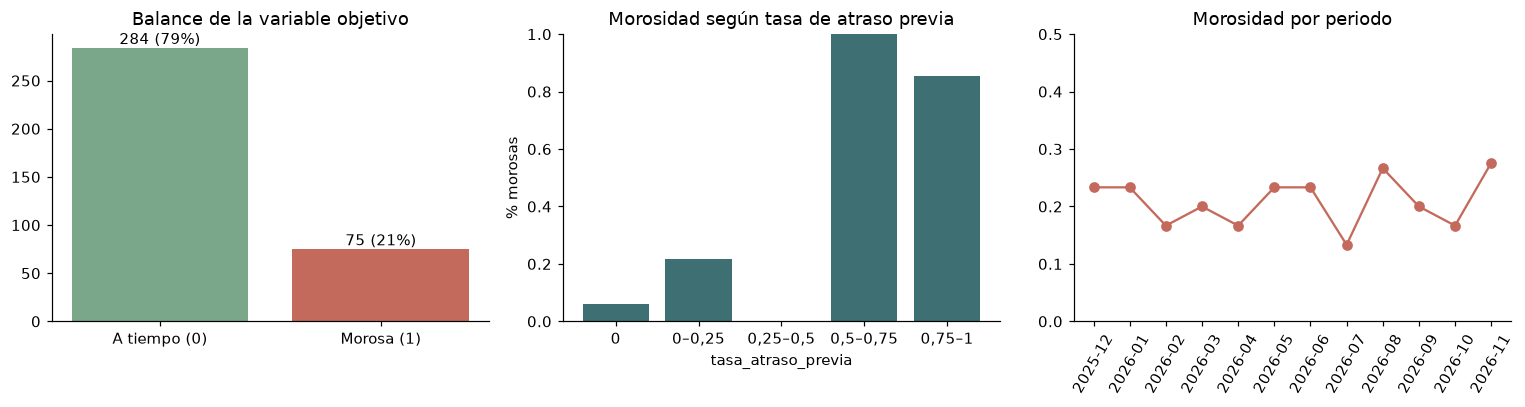

,pagos_atrasados_previos,atrasos_previos_total,tasa_atraso_previa,dias_atraso_promedio_previo
count,359.00,359.00,359.00,359.00
mean,0.52,1.14,0.19,3.12
std,0.94,2.25,0.34,7.68
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00
75%,1.00,1.00,0.22,1.00
max,3.00,11.00,1.00,38.18


In [5]:
# Bloque 4 · EDA: balance de clases y relación historial–morosidad
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
conteo = y.value_counts().sort_index()
ax[0].bar(['A tiempo (0)', 'Morosa (1)'], conteo.values, color=['#7aa68a', '#c46a5c'])
for i, v in enumerate(conteo.values): ax[0].text(i, v + 4, f'{v} ({v / len(y):.0%})', ha='center')
ax[0].set_title('Balance de la variable objetivo')
tasa_hist = pd.cut(X_todo['tasa_atraso_previa'], [-0.01, 0, 0.25, 0.5, 0.75, 1], labels=['0', '0–0,25', '0,25–0,5', '0,5–0,75', '0,75–1'])
g = y.groupby(tasa_hist, observed=True).mean()
ax[1].bar(g.index.astype(str), g.values, color='#3d6f73'); ax[1].set_ylim(0, 1)
ax[1].set_title('Morosidad según tasa de atraso previa'); ax[1].set_xlabel('tasa_atraso_previa'); ax[1].set_ylabel('% morosas')
m = y.groupby(df['periodo'].dt.strftime('%Y-%m')).mean()
ax[2].plot(m.index, m.values, marker='o', color='#c46a5c'); ax[2].tick_params(axis='x', rotation=60); ax[2].set_ylim(0, 0.5)
ax[2].set_title('Morosidad por periodo')
plt.tight_layout(); plt.savefig(RESULTADOS / 'eda.png', bbox_inches='tight'); plt.show()
display(X_todo[VARIABLES_MODELO].describe().round(2))

- **Desbalance** (≈ 21 % morosas): *accuracy* no basta; se reportan precision, recall y F1 y se prioriza recall (falsos negativos = cuotas morosas sin recordatorio).
- **Relación plausible**: quien se atrasó antes tiende a atrasarse de nuevo (tasa previa alta → morosidad alta). Es la señal que usa el modelo.
- **Sin estacionalidad clara**: la morosidad mensual oscila entre 13 % y 28 %; con 12 meses no se modela estacionalidad.

## 5. Partición temporal
Cronológica (no aleatoria) para no predecir el pasado con el futuro: 9 primeros meses entrenamiento, mes 10 validación y meses 11–12 prueba (contrato APF2). El ajuste de hiperparámetros usa validación cruzada **temporal** dentro de entrenamiento (cada mes 5–9 se predice con los meses anteriores).

In [6]:
# Bloque 5 · Partición
particion = np.select([indice_periodo < 9, indice_periodo == 9], ['entrenamiento', 'validacion'], 'prueba')
X = X_todo[VARIABLES_MODELO]
m_ent, m_val, m_pru = particion == 'entrenamiento', particion == 'validacion', particion == 'prueba'
tabla = pd.DataFrame({p: {'periodos': f"{df.loc[particion == p, 'periodo'].min():%Y-%m} a {df.loc[particion == p, 'periodo'].max():%Y-%m}",
                          'filas': int((particion == p).sum()), 'morosas': int(y[particion == p].sum()),
                          '% morosas': f"{y[particion == p].mean():.1%}"} for p in ['entrenamiento', 'validacion', 'prueba']}).T
display(tabla)
# Validación cruzada temporal dentro de entrenamiento: predecir el mes k con los meses < k (k = 5..9).
cv_temporal = [(np.where(indice_periodo[m_ent] < k)[0], np.where(indice_periodo[m_ent] == k)[0]) for k in range(4, 9)]
print('Pliegues temporales:', [(len(a), len(b)) for a, b in cv_temporal])
X_ent, y_ent = X[m_ent], y[m_ent]

,periodos,filas,morosas,% morosas
entrenamiento,2025-12 a 2026-08,270,56,20.7%
validacion,2026-09 a 2026-09,30,6,20.0%
prueba,2026-10 a 2026-11,59,13,22.0%


Pliegues temporales: [(120, 30), (150, 30), (180, 30), (210, 30), (240, 30)]


## 6. Modelos, ajuste de hiperparámetros y umbral

- **Líneas base**: `DummyClassifier` (clase mayoritaria y estratificado) y una **regla heurística** de negocio: recordar a quien tuvo al menos un atraso en los 3 meses previos.
- **Regresión logística** (escalado estándar, regularización L2) y **árbol de decisión** (profundidad y hojas mínimas limitadas), dentro de `Pipeline` + `ColumnTransformer` para que el preprocesamiento se ajuste solo con entrenamiento.
- **Búsqueda en grilla** con la validación cruzada temporal y `average_precision` (calidad del ranking de riesgo, independiente del umbral).
- **Umbral**: con las predicciones fuera de muestra de esa validación cruzada (meses 5–9, solo entrenamiento) se elige el **mayor umbral que logra recall ≥ 0,80**. El conjunto de prueba no interviene.

In [7]:
# Bloque 6 · Entrenamiento y ajuste (solo datos de entrenamiento)
def pipeline(modelo, escalar):
    pre = ColumnTransformer([('num', StandardScaler() if escalar else 'passthrough', VARIABLES_MODELO)])
    return Pipeline([('preprocesamiento', pre), ('modelo', modelo)])

candidatos = {
    'Regresión logística': (pipeline(LogisticRegression(max_iter=2000, random_state=SEMILLA), True),
                            {'modelo__C': [0.01, 0.1, 1, 10], 'modelo__class_weight': [None, 'balanced']}),
    'Árbol de decisión': (pipeline(DecisionTreeClassifier(random_state=SEMILLA), False),
                          {'modelo__max_depth': [2, 3, 4, 5], 'modelo__min_samples_leaf': [5, 10, 20], 'modelo__class_weight': [None, 'balanced']}),
}
ajustados, umbrales, oof = {}, {}, {}
for nombre, (pipe, grilla) in candidatos.items():
    busqueda = GridSearchCV(pipe, grilla, cv=cv_temporal, scoring='average_precision', refit=True)
    busqueda.fit(X_ent, y_ent)
    ajustados[nombre] = busqueda.best_estimator_
    # Predicciones fuera de muestra con los mejores hiperparámetros (mismos pliegues temporales)
    p_oof, y_oof = [], []
    for a, b in cv_temporal:
        m = clone(busqueda.best_estimator_).fit(X_ent.iloc[a], y_ent.iloc[a])
        p_oof.append(m.predict_proba(X_ent.iloc[b])[:, 1]); y_oof.append(y_ent.iloc[b].values)
    p_oof, y_oof = np.concatenate(p_oof), np.concatenate(y_oof)
    oof[nombre] = (y_oof, p_oof)
    cumple = [t for t in np.unique(p_oof) if recall_score(y_oof, (p_oof >= t).astype(int)) >= META_RECALL]
    umbrales[nombre] = float(max(cumple)) if cumple else 0.5
    print(f'{nombre}: mejores hiperparámetros {busqueda.best_params_} · AP CV {busqueda.best_score_:.3f} · umbral {umbrales[nombre]:.3f}')

# Líneas base
base_mayoritaria = DummyClassifier(strategy='most_frequent').fit(X_ent, y_ent)
base_estratificada = DummyClassifier(strategy='stratified', random_state=SEMILLA).fit(X_ent, y_ent)
regla = lambda Xp: (Xp['pagos_atrasados_previos'] >= 1).astype(int).values

Regresión logística: mejores hiperparámetros {'modelo__C': 10, 'modelo__class_weight': None} · AP CV 0.871 · umbral 0.226


Árbol de decisión: mejores hiperparámetros {'modelo__class_weight': None, 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10} · AP CV 0.781 · umbral 0.364


## 7. Comparación en entrenamiento y validación (selección del modelo)
Regla de selección fijada antes de mirar la prueba: entre los modelos con **recall ≥ 0,80 en validación**, el de mayor **F1 en validación**; si la diferencia es menor a 0,02 se prefiere el más interpretable (regresión logística).

In [8]:
# Bloque 7 · Métricas en entrenamiento, validación cruzada temporal y validación
def metricas(y_real, y_pred, prob=None):
    r = {'accuracy': accuracy_score(y_real, y_pred), 'precision': precision_score(y_real, y_pred, zero_division=0),
         'recall': recall_score(y_real, y_pred, zero_division=0), 'f1': f1_score(y_real, y_pred, zero_division=0)}
    if prob is not None: r['avg_precision'] = average_precision_score(y_real, prob)
    return r

def predecir(nombre, modelo, Xp):
    if nombre == 'Regla: atraso en 3 meses previos': return regla(Xp), None
    if nombre.startswith('Dummy'): return modelo.predict(Xp), None
    p = modelo.predict_proba(Xp)[:, 1]
    return (p >= umbrales[nombre]).astype(int), p

modelos = {'Dummy (clase mayoritaria)': base_mayoritaria, 'Dummy (estratificado)': base_estratificada,
           'Regla: atraso en 3 meses previos': None, **ajustados}
filas = []
for nombre, modelo in modelos.items():
    for conjunto, (Xc, yc) in {'entrenamiento': (X_ent, y_ent), 'validacion': (X[m_val], y[m_val])}.items():
        pred, prob = predecir(nombre, modelo, Xc)
        filas.append({'modelo': nombre, 'conjunto': conjunto, **metricas(yc, pred, prob)})
    if nombre in oof:
        y_o, p_o = oof[nombre]
        filas.append({'modelo': nombre, 'conjunto': 'cv temporal (fuera de muestra)', **metricas(y_o, (p_o >= umbrales[nombre]).astype(int), p_o)})
comparacion = pd.DataFrame(filas).round(3)
comparacion.to_csv(RESULTADOS / 'metricas_entrenamiento_validacion.csv', index=False)
display(comparacion)

val = comparacion[comparacion['conjunto'] == 'validacion'].set_index('modelo')
aptos = val.loc[list(ajustados)][val.loc[list(ajustados), 'recall'] >= META_RECALL]
if aptos.empty:
    aptos = val.loc[list(ajustados)]
    print('Ningún modelo alcanza recall 0,80 en validación: se elige por F1 y se declara el incumplimiento.')
mejor = aptos['f1'].idxmax()
if mejor != 'Regresión logística' and 'Regresión logística' in aptos.index and aptos.loc[mejor, 'f1'] - aptos.loc['Regresión logística', 'f1'] < 0.02:
    mejor = 'Regresión logística'
SELECCIONADO = mejor
print(f'Modelo seleccionado: {SELECCIONADO} (umbral {umbrales[SELECCIONADO]:.3f})')
brecha = comparacion.pivot(index='modelo', columns='conjunto', values='f1').loc[list(ajustados)]
print('Control de sobreajuste (F1):'); display(brecha)

,modelo,conjunto,accuracy,precision,recall,f1,avg_precision
0,Dummy (clase mayoritaria),entrenamiento,0.793,0.000,0.000,0.000,NaN
1,Dummy (clase mayoritaria),validacion,0.800,0.000,0.000,0.000,NaN
2,Dummy (estratificado),entrenamiento,0.644,0.155,0.161,0.158,NaN
3,Dummy (estratificado),validacion,0.733,0.250,0.167,0.200,NaN
4,Regla: atraso en 3 meses previos,entrenamiento,0.785,0.486,0.643,0.554,NaN
5,Regla: atraso en 3 meses previos,validacion,0.800,0.500,0.833,0.625,NaN
6,Regresión logística,entrenamiento,0.893,0.729,0.768,0.748,0.732
7,Regresión logística,validacion,0.933,0.750,1.000,0.857,0.958
8,Regresión logística,cv temporal (fuera de muestra),0.920,0.806,0.806,0.806,0.826
9,Árbol de decisión,entrenamiento,0.907,0.782,0.768,0.775,0.778


Modelo seleccionado: Regresión logística (umbral 0.226)
Control de sobreajuste (F1):


conjunto,cv temporal (fuera de muestra),entrenamiento,validacion
modelo,,,
Regresión logística,0.806,0.748,0.857
Árbol de decisión,0.847,0.775,0.857


In [9]:
# Bloque 7b · Variables auditadas (validación cruzada temporal, solo entrenamiento): ¿aportan algo legítimo?
variantes = {'principal': VARIABLES_MODELO, '+ metodo_pago_ultimo': VARIABLES_MODELO + ['metodo_pago_ultimo'],
             '+ mes y cuotas_previas': VARIABLES_MODELO + ['mes', 'cuotas_previas']}
filas = []
for nombre, cols in variantes.items():
    cat = [c for c in cols if c == 'metodo_pago_ultimo']; num = [c for c in cols if c not in cat]
    pre = ColumnTransformer([('num', StandardScaler(), num)] + ([('cat', OneHotEncoder(handle_unknown='ignore'), cat)] if cat else []))
    est = clone(ajustados[SELECCIONADO]).named_steps['modelo']
    Xv = X_todo.loc[m_ent, cols]
    probs, reales = [], []
    for a_, b_ in cv_temporal:
        m_ = Pipeline([('pre', clone(pre)), ('modelo', clone(est))]).fit(Xv.iloc[a_], y_ent.iloc[a_])
        probs.append(m_.predict_proba(Xv.iloc[b_])[:, 1]); reales.append(y_ent.iloc[b_].values)
    filas.append({'variante': nombre, 'avg_precision_cv_temporal': round(average_precision_score(np.concatenate(reales), np.concatenate(probs)), 3)})
display(pd.DataFrame(filas))
print('Si una variante mejora, puede deberse a artefactos de la semilla (método asignado por número de unidad; meses como reloj): se mantiene la variante principal.')

,variante,avg_precision_cv_temporal
0,principal,0.826
1,+ metodo_pago_ultimo,0.812
2,+ mes y cuotas_previas,0.810


Si una variante mejora, puede deberse a artefactos de la semilla (método asignado por número de unidad; meses como reloj): se mantiene la variante principal.


## 8. Evaluación final en prueba (una sola vez)
El modelo seleccionado se reentrena con entrenamiento + validación (mismos hiperparámetros y umbral) y se evalúa **una vez** en los meses 11–12. Las líneas base se reportan en el mismo conjunto para comparar.

,modelo,accuracy,precision,recall,f1,avg_precision
0,Dummy (clase mayoritaria),0.780,0.000,0.000,0.000,NaN
1,Dummy (estratificado),0.644,0.167,0.154,0.160,NaN
2,Regla: atraso en 3 meses previos,0.746,0.450,0.692,0.545,NaN
3,Regresión logística ★,0.847,0.611,0.846,0.710,0.809
4,Árbol de decisión,0.881,0.688,0.846,0.759,0.733


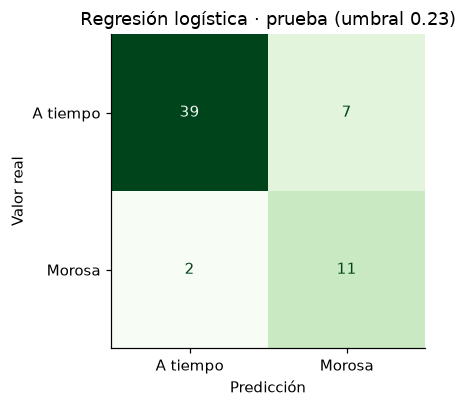

VP=11 FN=2 FP=7 VN=39 · recall 0.85 (meta 0.80)


In [10]:
# Bloque 8 · Prueba final
m_ev = m_ent | m_val
final = clone(ajustados[SELECCIONADO]).fit(X[m_ev], y[m_ev])
UMBRAL = umbrales[SELECCIONADO]
prob_pru = final.predict_proba(X[m_pru])[:, 1]
pred_pru = (prob_pru >= UMBRAL).astype(int)

filas = []
for nombre, modelo in modelos.items():
    if nombre == SELECCIONADO:
        pred, prob = pred_pru, prob_pru
    elif nombre.startswith('Dummy'):
        pred, prob = clone(modelo).fit(X[m_ev], y[m_ev]).predict(X[m_pru]), None
    elif nombre.startswith('Regla'):
        pred, prob = regla(X[m_pru]), None
    else:
        otro = clone(ajustados[nombre]).fit(X[m_ev], y[m_ev]); prob = otro.predict_proba(X[m_pru])[:, 1]; pred = (prob >= umbrales[nombre]).astype(int)
    filas.append({'modelo': nombre + (' ★' if nombre == SELECCIONADO else ''), **metricas(y[m_pru], pred, prob)})
tabla_prueba = pd.DataFrame(filas).round(3)
tabla_prueba.to_csv(RESULTADOS / 'metricas_prueba.csv', index=False)
display(tabla_prueba)

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay(confusion_matrix(y[m_pru], pred_pru), display_labels=['A tiempo', 'Morosa']).plot(ax=ax, colorbar=False, cmap='Greens')
ax.set_xlabel('Predicción'); ax.set_ylabel('Valor real')
ax.set_title(f'{SELECCIONADO} · prueba (umbral {UMBRAL:.2f})'); plt.tight_layout()
plt.savefig(RESULTADOS / 'matriz_confusion_prueba.png', bbox_inches='tight'); plt.show()
vn, fp, fn, vp = confusion_matrix(y[m_pru], pred_pru).ravel()
print(f'VP={vp} FN={fn} FP={fp} VN={vn} · recall {vp / (vp + fn):.2f} (meta {META_RECALL:.2f})')

## 9. Análisis de errores e interpretación

,tipo,unidad_ref,periodo,probabilidad,pagos_atrasados_previos,atrasos_previos_total,tasa_atraso_previa,dias_atraso_promedio_previo,perfil_unidad (auditoría),hipotesis
305,Falso positivo,U-35618e2596,2026-10-01,0.502,0.0,2.0,0.2000,1.10,ocasional (1–4),Unidad ocasional con atrasos previos: el model...
314,Falso positivo,U-736572b855,2026-10-01,0.502,0.0,2.0,0.2000,1.10,ocasional (1–4),Unidad ocasional con atrasos previos: el model...
324,Falso positivo,U-c5a734313d,2026-10-01,0.998,3.0,9.0,0.9000,28.10,crónica (≥ 5),Unidad crónica que esta vez pagó a tiempo (en ...
325,Falso positivo,U-cb22960dae,2026-10-01,0.982,3.0,9.0,0.9000,10.60,crónica (≥ 5),Unidad crónica que esta vez pagó a tiempo (en ...
335,Falso positivo,U-35618e2596,2026-11-01,0.478,0.0,2.0,0.1818,1.00,ocasional (1–4),Unidad ocasional con atrasos previos: el model...
337,Falso positivo,U-467eff7f57,2026-11-01,0.289,1.0,3.0,0.2727,1.09,ocasional (1–4),Unidad ocasional con atrasos previos: el model...
339,Falso negativo,U-5d73d3162c,2026-11-01,0.102,1.0,2.0,0.1818,0.64,ocasional (1–4),Historial con pocos atrasos: la probabilidad n...
347,Falso positivo,U-8b38539bc6,2026-11-01,0.300,1.0,3.0,0.2727,1.45,ocasional (1–4),Unidad ocasional con atrasos previos: el model...
357,Falso negativo,U-e7898ec111,2026-11-01,0.065,0.0,0.0,0.0000,0.00,ocasional (1–4),Unidad sin atrasos previos: el atraso no tiene...


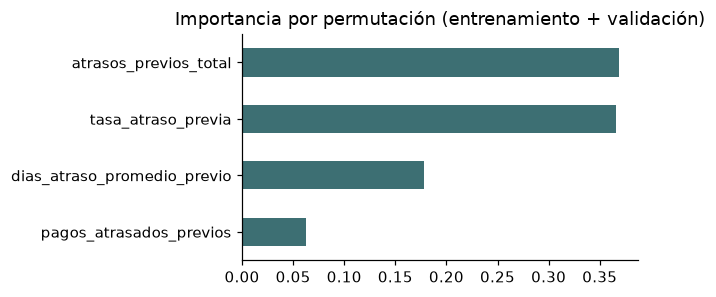

pagos_atrasados_previos       -1.867
atrasos_previos_total          1.505
tasa_atraso_previa             1.513
dias_atraso_promedio_previo    0.997
Name: coeficiente (variables escaladas), dtype: float64

Nota: las cuatro variables están muy correlacionadas (todas miden el historial de atrasos), así que los coeficientes individuales no se interpretan aislados (un signo negativo compensa a otra variable). Para explicar el modelo se usa la importancia por permutación.


,pagos_atrasados_previos,atrasos_previos_total,tasa_atraso_previa,dias_atraso_promedio_previo
pagos_atrasados_previos,1.00,0.90,0.93,0.82
atrasos_previos_total,0.90,1.00,0.83,0.82
tasa_atraso_previa,0.93,0.83,1.00,0.83
dias_atraso_promedio_previo,0.82,0.82,0.83,1.00


In [11]:
# Bloque 9 · Casos mal clasificados en prueba (con hipótesis) e importancia de variables
errores = df.loc[m_pru, ['unidad_ref', 'periodo', 'moroso']].copy()
errores[VARIABLES_MODELO] = X.loc[m_pru].values
errores['probabilidad'] = prob_pru.round(3)
errores['prediccion'] = pred_pru
errores['perfil_unidad (auditoría)'] = errores['unidad_ref'].map(perfil['grupo_observado'].astype(str))
errores = errores[errores['moroso'] != errores['prediccion']]
errores['tipo'] = np.where(errores['moroso'] == 1, 'Falso negativo', 'Falso positivo')
def hipotesis(r):
    if r['tipo'] == 'Falso negativo' and r['atrasos_previos_total'] == 0:
        return 'Unidad sin atrasos previos: el atraso no tiene antecedentes en el historial (regla ocasional de la semilla o primer atraso).'
    if r['tipo'] == 'Falso negativo':
        return 'Historial con pocos atrasos: la probabilidad no supera el umbral; el atraso ocasional sigue una regla no observable.'
    if r['tasa_atraso_previa'] >= 0.5:
        return 'Unidad crónica que esta vez pagó a tiempo (en la semilla los crónicos pagan a tiempo algunos meses).'
    return 'Unidad ocasional con atrasos previos: el modelo eleva su riesgo, pero esta vez pagó a tiempo (sus atrasos siguen una regla no observable).'
errores['hipotesis'] = errores.apply(hipotesis, axis=1)
errores.to_csv(RESULTADOS / 'errores_prueba.csv', index=False)
display(errores[['tipo', 'unidad_ref', 'periodo', 'probabilidad'] + VARIABLES_MODELO + ['perfil_unidad (auditoría)', 'hipotesis']])

imp = permutation_importance(final, X[m_ev], y[m_ev], scoring='average_precision', n_repeats=30, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=VARIABLES_MODELO).sort_values()
importancia.to_csv(RESULTADOS / 'importancia_variables.csv')
fig, ax = plt.subplots(figsize=(6, 2.8)); importancia.plot.barh(ax=ax, color='#3d6f73')
ax.set_title('Importancia por permutación (entrenamiento + validación)'); plt.tight_layout()
plt.savefig(RESULTADOS / 'importancia_variables.png', bbox_inches='tight'); plt.show()
est = final.named_steps['modelo']
if hasattr(est, 'coef_'):
    display(pd.Series(est.coef_[0], index=VARIABLES_MODELO, name='coeficiente (variables escaladas)').round(3))
    print('Nota: las cuatro variables están muy correlacionadas (todas miden el historial de atrasos), así que los coeficientes '
          'individuales no se interpretan aislados (un signo negativo compensa a otra variable). Para explicar el modelo se usa la importancia por permutación.')
    display(X[m_ev].corr().round(2))
else:
    print(export_text(est, feature_names=VARIABLES_MODELO))

## 10. Exportación del modelo e inferencia sobre un registro nuevo

In [12]:
# Bloque 10 · Exportar pipeline + metadatos y predecir un registro con el esquema del MVP
VERSION = 'v1'
ruta_modelo = MODELO_DIR / f'modelo_morosidad_{VERSION}.joblib'
joblib.dump(final, ruta_modelo)
metadatos = {
    'modelo_version': VERSION, 'algoritmo': SELECCIONADO, 'umbral': round(UMBRAL, 4),
    'caracteristicas': VARIABLES_MODELO, 'hiperparametros': {k: v for k, v in final.named_steps['modelo'].get_params().items() if k in ('C', 'class_weight', 'max_depth', 'min_samples_leaf')},
    'momento_prediccion': 'primer día del periodo, antes del vencimiento (fecha_corte = periodo)',
    'entrenado_con': {'archivo': str(RUTA_DATOS), 'sha256': sha256, 'filas': int(m_ev.sum()), 'periodos': 'meses 1–10', 'origen': 'simulado'},
    'metricas_validacion': val.loc[SELECCIONADO, ['accuracy', 'precision', 'recall', 'f1']].round(3).to_dict(),
    'metricas_prueba': tabla_prueba.set_index('modelo').loc[SELECCIONADO + ' ★', ['accuracy', 'precision', 'recall', 'f1']].round(3).to_dict(),
    'versiones': {'python': sys.version.split()[0], 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__},
    'limitaciones': 'Datos 100 % simulados con reglas deterministas: resultados indicativos, no generalizables a vecinos reales.',
}
(MODELO_DIR / f'modelo_morosidad_{VERSION}.json').write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(metadatos, ensure_ascii=False, indent=2))

from inferencia import cargar_modelo, predecir_registro
registro_nuevo = {   # mismo esquema que devuelve ml_caracteristicas_cuotas en Supabase
    'cuota_id': '00000000-0000-4000-8000-000000000000', 'unidad_ref': 'U-ejemplo0001', 'periodo': '2026-12-01',
    'fecha_vencimiento': '2026-12-10', 'pagos_atrasados_previos': 2, 'cuotas_previas': 12,
    'atrasos_previos_total': 5, 'tasa_atraso_previa': 0.4167, 'dias_atraso_promedio_previo': 4.5,
    'metodo_pago_ultimo': 'yape_qr', 'es_simulado': True}
print(json.dumps(predecir_registro(cargar_modelo(MODELO_DIR), registro_nuevo), ensure_ascii=False, indent=2))

{
  "modelo_version": "v1",
  "algoritmo": "Regresión logística",
  "umbral": 0.2258,
  "caracteristicas": [
    "pagos_atrasados_previos",
    "atrasos_previos_total",
    "tasa_atraso_previa",
    "dias_atraso_promedio_previo"
  ],
  "hiperparametros": {
    "C": 10,
    "class_weight": null
  },
  "momento_prediccion": "primer día del periodo, antes del vencimiento (fecha_corte = periodo)",
  "entrenado_con": {
    "archivo": "..\\dataset_apf3\\dataset_arcomunity_apf3.csv",
    "sha256": "12bfe4d0317c0996c1702e6513293cb15bd3587f3ef57aaea8fbd395bdf71dfa",
    "filas": 300,
    "periodos": "meses 1–10",
    "origen": "simulado"
  },
  "metricas_validacion": {
    "accuracy": 0.933,
    "precision": 0.75,
    "recall": 1.0,
    "f1": 0.857
  },
  "metricas_prueba": {
    "accuracy": 0.847,
    "precision": 0.611,
    "recall": 0.846,
    "f1": 0.71
  },
  "versiones": {
    "python": "3.12.10",
    "scikit-learn": "1.9.1",
    "pandas": "3.1.1",
    "numpy": "2.5.5"
  },
  "limitacione

## 11. Simulación de impacto de los recordatorios (**HIPOTÉTICA**)

> ⚠️ Escenario contrafactual **simulado**. No es un resultado medido: combina lo que el modelo detectó en el conjunto de prueba (medido) con un **supuesto** de efectividad de los recordatorios (no medido). Solo un piloto real (por ejemplo, recordatorios A/B en la junta) podría confirmar una reducción de la morosidad.

Supuestos explícitos:
1. Cada cuota marcada en riesgo recibe un recordatorio del administrador 1–9 días antes del vencimiento.
2. Una fracción **e** de las cuotas morosas que reciben recordatorio pasa a pagarse a tiempo (e = 10 %, 20 %, 30 %: rango ilustrativo, sin calibrar con datos de la junta).
3. Los recordatorios a cuotas que igual se pagarían a tiempo (falsos positivos) no cambian nada y solo cuestan tiempo.

,efectividad_supuesta,estrategia,recordatorios,morosas_avisadas (medido),morosas_esperadas (simulado),reduccion_morosidad (simulado),recordatorios_por_morosa_evitada
0,10%,Sin recordatorios,0,0,13.0,0.0%,NaN
1,10%,Recordar a todos,59,13,11.7,10.0%,45.4
2,10%,Regla: atraso en 3 meses previos,20,9,12.1,6.9%,22.2
3,10%,Modelo (Regresión logística),18,11,11.9,8.5%,16.4
4,20%,Sin recordatorios,0,0,13.0,0.0%,NaN
5,20%,Recordar a todos,59,13,10.4,20.0%,22.7
6,20%,Regla: atraso en 3 meses previos,20,9,11.2,13.8%,11.1
7,20%,Modelo (Regresión logística),18,11,10.8,16.9%,8.2
8,30%,Sin recordatorios,0,0,13.0,0.0%,NaN
9,30%,Recordar a todos,59,13,9.1,30.0%,15.1


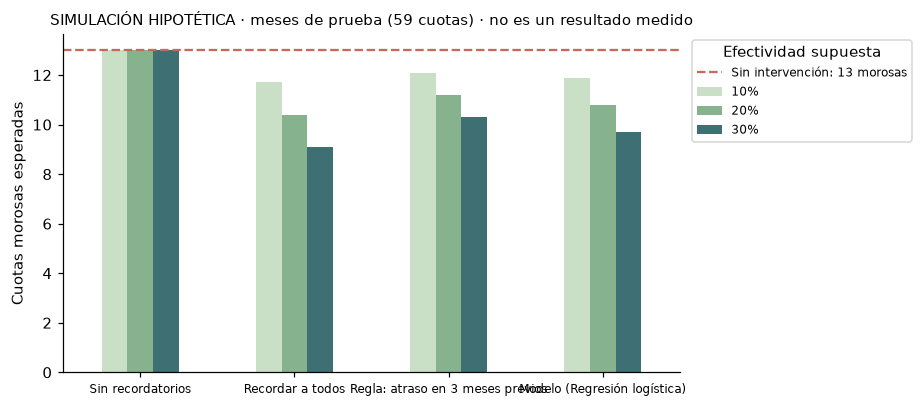

In [13]:
# Bloque 11 · Escenarios (HIPOTÉTICOS) sobre las 59 cuotas de prueba
morosas = int(y[m_pru].sum())
estrategias = {
    'Sin recordatorios': (0, 0),
    'Recordar a todos': (int(m_pru.sum()), morosas),
    'Regla: atraso en 3 meses previos': (int(regla(X[m_pru]).sum()), int((regla(X[m_pru]) & y[m_pru].values).sum())),
    f'Modelo ({SELECCIONADO})': (int(pred_pru.sum()), int(vp)),
}
filas = []
for e in [0.10, 0.20, 0.30]:
    for nombre, (recordatorios, morosas_avisadas) in estrategias.items():
        evitadas = e * morosas_avisadas
        filas.append({'efectividad_supuesta': f'{e:.0%}', 'estrategia': nombre, 'recordatorios': recordatorios,
                      'morosas_avisadas (medido)': morosas_avisadas, 'morosas_esperadas (simulado)': round(morosas - evitadas, 1),
                      'reduccion_morosidad (simulado)': f'{evitadas / morosas:.1%}',
                      'recordatorios_por_morosa_evitada': round(recordatorios / evitadas, 1) if evitadas else None})
simulacion = pd.DataFrame(filas)
simulacion.to_csv(RESULTADOS / 'simulacion_impacto_HIPOTETICA.csv', index=False)
display(simulacion)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
tabla_g = simulacion.pivot(index='estrategia', columns='efectividad_supuesta', values='morosas_esperadas (simulado)').loc[list(estrategias)]
tabla_g.plot.bar(ax=ax, color=['#c9dfc6', '#86b28d', '#3d6f73'], rot=0)
ax.axhline(morosas, ls='--', color='#c46a5c', label=f'Sin intervención: {morosas} morosas')
ax.set_ylabel('Cuotas morosas esperadas'); ax.set_xlabel('')
ax.set_title('SIMULACIÓN HIPOTÉTICA · meses de prueba (59 cuotas) · no es un resultado medido', fontsize=10)
ax.legend(title='Efectividad supuesta', fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1)); plt.xticks(fontsize=8); plt.tight_layout()
plt.savefig(RESULTADOS / 'simulacion_impacto_HIPOTETICA.png', bbox_inches='tight'); plt.show()

**Cómo leerlo.** El modelo concentra los recordatorios en menos cuotas que «recordar a todos» y avisa a más morosas que no hacer nada; el beneficio en morosidad depende por completo del supuesto de efectividad. Lo **medido** es cuántas morosas detecta el modelo (recall); la **reducción de morosidad** es simulada y debe validarse con un piloto antes de afirmarse.

## 12. Resumen reproducible

In [14]:
resumen = {'dataset_sha256': sha256, 'filas': len(df), 'morosas': int(y.sum()), 'seleccionado': SELECCIONADO,
           'umbral': round(UMBRAL, 4), 'validacion': metadatos['metricas_validacion'], 'prueba': metadatos['metricas_prueba']}
(RESULTADOS / 'resumen.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(resumen, ensure_ascii=False, indent=2))

{
  "dataset_sha256": "12bfe4d0317c0996c1702e6513293cb15bd3587f3ef57aaea8fbd395bdf71dfa",
  "filas": 359,
  "morosas": 75,
  "seleccionado": "Regresión logística",
  "umbral": 0.2258,
  "validacion": {
    "accuracy": 0.933,
    "precision": 0.75,
    "recall": 1.0,
    "f1": 0.857
  },
  "prueba": {
    "accuracy": 0.847,
    "precision": 0.611,
    "recall": 0.846,
    "f1": 0.71
  }
}
